## Этап 3. Рейтинг с объяснением весов и правил обработки пропусков

**Структура ноутбука:**
1. Загрузка витрины и проверки целостности
2. Какие показатели сильнее всего влияют на топ (корреляция + вклад в дисперсию)
3. Профиль топ-10: спрос / инфраструктура / зима / доступность / цена
4. Квадранты «индекс × уверенность»
5. Сценарии весов и устойчивость топа
6. OSM-overlap: где баллы не независимы
7. Проверка гипотезы «зимняя доля вместо общего потока»
8. Рекомендации заказчику
9. Автопроверки ТЗ (раздел 16)
10. Ограничения модели

In [31]:
#import micropip
#await micropip.install ('seaborn')

!pip install -r requirements.txt

ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'


In [32]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from numpy import log1p

#BASE = Path(r"C:\Users\dak\OneDrive\Документы\3 Горнолыжные курорты\Travel_Designer_Resort_Ranking")
BASE = Path (".")

RAW = BASE / "data" / "raw"
PROCESSED = BASE / "data" / "processed"

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## 1. Загрузка витрины и проверка целостности

In [33]:
with open(PROCESSED / "model_data.json", encoding="utf-8-sig") as f:
    model_data = json.load(f)

model_df = pd.DataFrame(model_data["model_rows"])
weights = model_data["weights"]

with open(PROCESSED / "rosstat_enrichment.json", encoding="utf-8-sig") as f:
    enrichment = json.load(f)

enrich_df = pd.DataFrame(enrichment["records"])

print("model_df:", model_df.shape)
print("enrich_df:", enrich_df.shape)
print("Веса:", weights)

model_df: (32, 43)
enrich_df: (20, 17)
Веса: {'region_trips': 25.0, 'region_growth': 10.0, 'avg_stay': 5.0, 'pistes': 10.0, 'lifts': 7.0, 'lodging': 5.0, 'amenities': 3.0, 'snow_days': 8.0, 'freezing_days': 6.0, 'snowfall': 6.0, 'airport': 8.0, 'transport': 2.0, 'price': 5.0}


In [34]:
assert len(model_df) == 32, "Не 32 курорта!"
assert model_df["resort_id"].nunique() == 32, "resort_id не уникальны!"
assert abs(sum(weights.values()) - 100) < 0.001, "Сумма весов != 100"

score_cols = [
    "region_trips_score", "region_growth_score", "avg_stay_score",
    "pistes_score", "lifts_score", "lodging_score", "amenities_score",
    "snow_days_score", "freezing_days_score", "snowfall_score",
    "airport_score", "transport_score", "price_score",
]
missing = [c for c in score_cols if c not in model_df.columns]
assert not missing, f"Нет колонок: {missing}"

# Воспроизводимость рангов и уверенности
assert "rank_default" in model_df.columns, "Нет rank_default"
assert "confidence_score" in model_df.columns, "Нет confidence_score"

# Пересчёт ранга и сверка с эталоном
recalc_rank = model_df["popularity_score_default"].rank(
    ascending=False, method="min"
).astype(int)
rank_diff = (recalc_rank - model_df["rank_default"]).abs().max()
assert rank_diff == 0, f"Ранги не воспроизводятся: max diff = {rank_diff}"
print(f"✅ rank_default воспроизводится (max diff = {rank_diff})")

print("✅ Все проверки пройдены. Готово к анализу.")

✅ rank_default воспроизводится (max diff = 0)
✅ Все проверки пройдены. Готово к анализу.


## 2. Какие 3 показателя сильнее всего влияют на топ

**2.1 Корреляция**  
Корреляция показывает **связь**, но не учитывает вес показателя.  
Она отвечает на вопрос «насколько показатель совпадает с итоговым
индексом», а не «насколько он двигает рейтинг».

In [35]:
#Корреляция с итоговым индексом
corr = (
    model_df[score_cols + ["popularity_score_default"]]
    .corr(numeric_only=True)["popularity_score_default"]
    .drop("popularity_score_default")
    .sort_values(ascending=False)
)

corr_df = corr.reset_index()
corr_df.columns = ["Показатель", "Корреляция с индексом"]
corr_df["Вес, %"] = corr_df["Показатель"].str.replace("_score", "").map(weights)
display(corr_df.round(3))

,Показатель,Корреляция с индексом,"Вес, %"
0,lifts_score,0.81,7.00
1,lodging_score,0.74,5.00
2,pistes_score,0.73,10.00
3,region_trips_score,0.72,25.00
4,amenities_score,0.72,3.00
5,transport_score,0.51,2.00
6,snowfall_score,0.43,6.00
7,avg_stay_score,0.40,5.00
8,region_growth_score,0.38,10.00
9,snow_days_score,0.29,8.00


По корреляции лидируют:
•	lifts_score (Линии подъемников): 0.81 — связь сильная (Но вес лишь 7%)
•	lodging_score (Объекты размещения): 0.74, pistes_score (Сегменты трас): 0.73, region_trips_score (Рег турпоток): 0.72 — сильная
•	freezing_days_score (Морозные дни): -0.75 — сильная обратная
•	price_score (Средняя цена ски-пасса): -0.56 — умеренная обратная

Что означают отрицательные корреляции:
•	freezing_days_score : -0.75 — курорты с большим числом морозных дней (Сибирь, Урал, Север) имеют более низкий итоговый индекс. Потому что у них, как правило, хуже с региональным турпотоком и доступностью. Это НЕ значит «морозы плохо влияют на курорт» — это значит «в холодных регионах меньше туристов по Росстату».
•	price_score: -0.56 — price_score считается через inverse (чем дешевле, тем выше балл). Отрицательная корреляция значит: чем дороже курорт, тем выше его итоговый индекс. Логично: дорогие курорты (Красная Поляна, Роза Хутор) — это крупные комплексы с инфраструктурой.


**1.2 Вклад в дисперсию**

In [36]:
#Вклад: вес × разброс
# Вклад = дисперсия взвешенного балла
contributions = {}
for col in score_cols:
    key = col.replace("_score", "")
    weighted = model_df[col] * weights[key]
    contributions[col] = weighted.var()

contrib_df = (
    pd.Series(contributions, name="Вклад в дисперсию")
    .sort_values(ascending=False)
    .reset_index()
    .rename(columns={"index": "Показатель"})
)
contrib_df["Доля, %"] = 100 * contrib_df["Вклад в дисперсию"] / contrib_df["Вклад в дисперсию"].sum()
display(contrib_df.round(2))

,Показатель,Вклад в дисперсию,"Доля, %"
0,region_trips_score,449907.15,54.33
1,region_growth_score,94504.53,11.41
2,pistes_score,61366.37,7.41
3,snow_days_score,59540.33,7.19
4,lifts_score,32501.81,3.92
5,snowfall_score,31476.39,3.80
6,airport_score,27320.72,3.30
7,freezing_days_score,22559.15,2.72
8,lodging_score,20405.93,2.46
9,avg_stay_score,13952.32,1.68


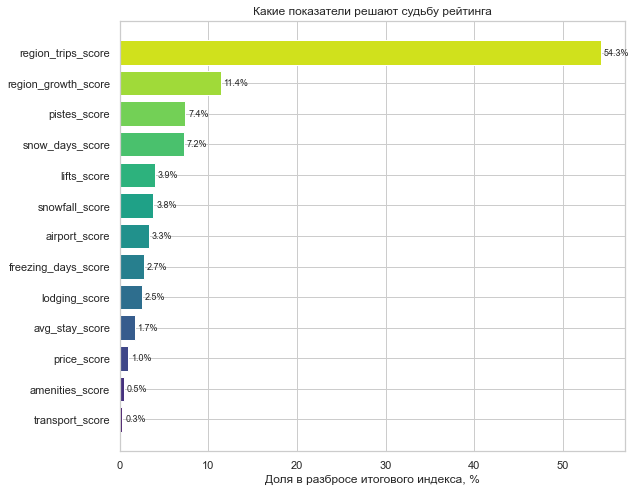

In [37]:
#визуализация
fig, ax = plt.subplots(figsize=(9, 7))
top_contrib = contrib_df.head(13).sort_values("Доля, %")
bars = ax.barh(top_contrib["Показатель"], top_contrib["Доля, %"],
               color=sns.color_palette("viridis", len(top_contrib)))
ax.set_xlabel("Доля в разбросе итогового индекса, %")
ax.set_title("Какие показатели решают судьбу рейтинга")
for bar, val in zip(bars, top_contrib["Доля, %"]):
    ax.text(val + 0.3, bar.get_y() + bar.get_height()/2,
            f"{val:.1f}%", va="center", fontsize=9)
plt.tight_layout()
plt.show()

In [38]:
top3 = contrib_df.head(3)
print("ТОП-3 влияющих показателя:")
for _, row in top3.iterrows():
    print(f" • {row['Показатель']:<25} {row['Доля, %']:>5.1f}% разброса индекса")

ТОП-3 влияющих показателя:
 • region_trips_score         54.3% разброса индекса
 • region_growth_score        11.4% разброса индекса
 • pistes_score                7.4% разброса индекса


Сильнее всего на порядок влияют `region_trips_score`, `region_growth_score`,
`pistes_score` — вместе они дают ~73% разброса итогового индекса.

Это значит, что качество данных о региональном турпотоке и инфраструктуре
критично для достоверности рейтинга. Погрешность в этих показателях
будет сдвигать курорты сильнее, чем в цене или транспорте.

**Почему корреляция и вклад расходятся:** у `region_trips_score`
корреляция 0.72 (не самая высокая), но вес 25 — максимальный, поэтому
вклад в дисперсию 54%. У `lifts_score` корреляция 0.81, но вес 7 —
вклад всего 3.9%. Для приоритизации данных используем вклад в дисперсию.

## 3. Профиль топ-10: из чего складывается позиция

5 компонентов — **взвешенное среднее внутри группы** (не вклад в итоговый
индекс). Показывает внутренний профиль курорта: сильные и слабые стороны.

In [39]:
##cчитаем 5 компонентов.В model_rows их нет, но легко посчитать из взвешенных баллов:

def component(row, keys):
    """Взвешенное среднее по группе показателей."""
    total_w = sum(weights[k] for k in keys)
    val = sum(row[f"{k}_score"] * weights[k] for k in keys)
    return val / total_w

demand_keys = ["region_trips", "region_growth", "avg_stay"]
infra_keys = ["pistes", "lifts", "lodging", "amenities"]
winter_keys = ["snow_days", "freezing_days", "snowfall"]
access_keys = ["airport", "transport"]
price_keys = ["price"]

model_df["demand_component"] = model_df.apply(lambda r: component(r, demand_keys), axis=1)
model_df["infra_component"] = model_df.apply(lambda r: component(r, infra_keys), axis=1)
model_df["winter_component"] = model_df.apply(lambda r: component(r, winter_keys), axis=1)
model_df["access_component"] = model_df.apply(lambda r: component(r, access_keys), axis=1)
model_df["price_component"] = model_df["price_score"] # один показатель

comp_cols = ["demand_component", "infra_component", "winter_component",
             "access_component", "price_component"]

model_df[["name_ru", "popularity_score_default"] + comp_cols].head()

,name_ru,popularity_score_default,demand_component,infra_component,winter_component,access_component,price_component
0,Газпром Поляна,73.79,80.91,97.02,52.51,46.53,40.26
1,Красная Поляна,71.69,80.91,90.58,52.17,46.97,30.93
2,Роза Хутор,71.57,80.91,94.41,55.70,44.61,0.00
3,Сорочаны,70.14,94.15,65.44,43.65,48.92,50.00
4,Архыз,59.25,51.48,71.83,80.00,24.54,44.98


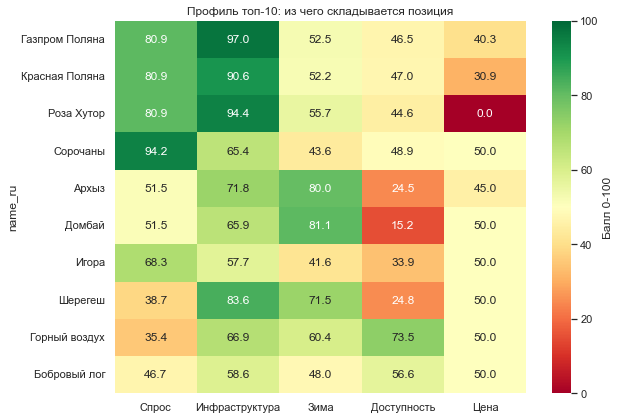

In [40]:
top10 = model_df.nlargest(10, "popularity_score_default").copy()
heat = top10.set_index("name_ru")[comp_cols]
heat.columns = ["Спрос", "Инфраструктура", "Зима", "Доступность", "Цена"]

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="RdYlGn",
            vmin=0, vmax=100, cbar_kws={"label": "Балл 0-100"}, ax=ax)
ax.set_title("Профиль топ-10: из чего складывается позиция")
plt.tight_layout()
plt.show()

In [41]:
for _, r in top10.iterrows():
    best = max(comp_cols, key=lambda c: r[c])
    worst = min(comp_cols, key=lambda c: r[c])
    print(f"{r['name_ru']:<20} лидер по {best.replace('_component',''):<12} "
          f"({r[best]:.1f}) | слабое место — {worst.replace('_component','')} ({r[worst]:.1f})")

Газпром Поляна       лидер по infra        (97.0) | слабое место — price (40.3)
Красная Поляна       лидер по infra        (90.6) | слабое место — price (30.9)
Роза Хутор           лидер по infra        (94.4) | слабое место — price (0.0)
Сорочаны             лидер по demand       (94.2) | слабое место — winter (43.6)
Архыз                лидер по winter       (80.0) | слабое место — access (24.5)
Домбай               лидер по winter       (81.1) | слабое место — access (15.2)
Игора                лидер по demand       (68.3) | слабое место — access (33.9)
Шерегеш              лидер по infra        (83.6) | слабое место — access (24.8)
Горный воздух        лидер по access       (73.5) | слабое место — demand (35.4)
Бобровый лог         лидер по infra        (58.6) | слабое место — demand (46.7)


**«Газпром Поляна»** — лидер за счёт инфраструктуры (97.01) и спроса (80.91), но слабая цена (40.3).  
**«Домбай»** держится в топ-10 только за счёт снега (81.1): по всем остальным компонентам значительно уступает.  
**«Игора»** поднялась за счёт спроса (68.3), но у неё слабейший доступность среди топ-10.

Все 3 курорта Краснодарского края получают одинаковый балл спроса (80.9), потому что используют одни и те же данные Росстата по региону. Индекс не различает спрос на Газпром Поляна vs Роза Хутор — это ограничение модели, а не свойство курортов

## 4. Квадранты «индекс × уверенность»

**Пороги обоснованы эмпирически по распределению индекса и confidence:**

- `INDEX_LEADER = 55` — медиана индекса (32 курорта, топ-16).
- `CONF_LEADER = 75` — порог, выше которого координаты не требуют
  ручной проверки (нет флага `manual_review_required`).
- `INDEX_RISKY = 50` — нижняя граница «потенциала» (верхняя половина).
- `CONF_RISKY = 60` — ниже этого порога есть флаги качества данных.

In [42]:
#Квадранты «индекс × уверенность».Курс с высоким баллом, но плохими данными — это риск. Если заказчик поставит его первым в каталог, а данные окажутся неверными, будет репутационный удар.

#Зафиксируем пороги
INDEX_LEADER = 55
CONF_LEADER = 75
INDEX_RISKY = 50
CONF_RISKY = 60

In [43]:
def classify(row):
    """Классификация по единым порогам (см. ячейку с константами)."""
    idx = row["popularity_score_default"]
    conf = row["confidence_score"]

    if idx >= INDEX_LEADER and conf >= CONF_LEADER:
        return "A. Лидеры (можно в каталог)"
    if idx >= INDEX_RISKY and conf < CONF_RISKY:
        return "B. Потенциал, но проверить"
    if idx < INDEX_LEADER and conf >= CONF_LEADER:
        return "C. Надёжные середняки"
    return "D. Низкий приоритет"

model_df["quadrant"] = model_df.apply(classify, axis=1)
print(model_df["quadrant"].value_counts())

quadrant
D. Низкий приоритет            18
A. Лидеры (можно в каталог)     7
B. Потенциал, но проверить      4
C. Надёжные середняки           3
Name: count, dtype: int64


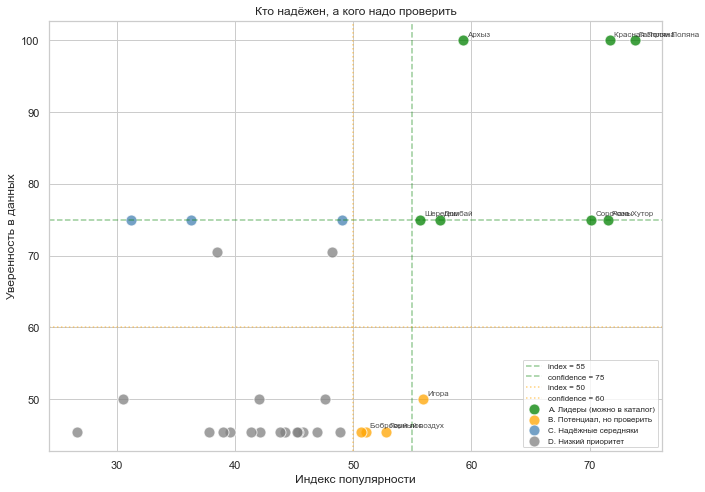

In [44]:
fig, ax = plt.subplots(figsize=(10, 7))

colors = {
    "A. Лидеры (можно в каталог)": "green",
    "B. Потенциал, но проверить": "orange",
    "C. Надёжные середняки": "steelblue",
    "D. Низкий приоритет": "gray",
}

for q, color in colors.items():
    sub = model_df[model_df["quadrant"] == q]
    ax.scatter(sub["popularity_score_default"], sub["confidence_score"],
               s=120, c=color, label=q, alpha=0.75, edgecolors="white")

# Линии порогов: вертикальная = лидер по индексу, горизонтальная = лидер по уверенности
ax.axvline(INDEX_LEADER, ls="--", c="green", alpha=0.4, label=f"index = {INDEX_LEADER}")
ax.axhline(CONF_LEADER, ls="--", c="green", alpha=0.4, label=f"confidence = {CONF_LEADER}")
ax.axvline(INDEX_RISKY, ls=":", c="orange", alpha=0.5, label=f"index = {INDEX_RISKY}")
ax.axhline(CONF_RISKY, ls=":", c="orange", alpha=0.5, label=f"confidence = {CONF_RISKY}")

# Подписи топ-10
for _, r in model_df.nlargest(10, "popularity_score_default").iterrows():
    ax.annotate(r["name_ru"], (r["popularity_score_default"], r["confidence_score"]),
                fontsize=8, alpha=0.8, xytext=(4, 4), textcoords="offset points")

ax.set_xlabel("Индекс популярности")
ax.set_ylabel("Уверенность в данных")
ax.set_title("Кто надёжен, а кого надо проверить")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

In [45]:
#Список «рискованных»

risky = model_df[model_df["quadrant"] == "B. Потенциал, но проверить"].copy()
print(f"Курортов в «рискованной зоне»: {len(risky)}\n")
display(risky[["resort_id", "name_ru", "region",
               "popularity_score_default", "confidence_score",
               "quality_flags"]].sort_values("popularity_score_default", ascending=False))

Курортов в «рискованной зоне»: 4



,resort_id,name_ru,region,popularity_score_default,confidence_score,quality_flags
6,R029,Игора,Ленинградская область,55.93,50.00,coordinates are proxy
8,R016,Горный воздух,Сахалинская область,52.79,45.45,check coordinates
9,R019,Бобровый лог,Красноярский край,51.09,45.45,check coordinates
10,R028,Губаха,Пермский край,50.69,45.45,check coordinates


## 4. Сценарии весов

Пересчитываем индекс при изменении весов. Выбранные веса увеличиваем,
остальные пропорционально уменьшаем — сумма остаётся 100.

In [46]:
#Функция сценариев
def scale_weights(base_weights, scale_up):
    """
    Увеличивает выбранные веса в scale_up раз.
    Остальные уменьшает пропорционально, чтобы сумма осталась 100.
    Гарантирует неотрицательность всех весов.
    """
    new_w = base_weights.copy()
    keys_up = list(scale_up.keys())
    delta = sum(base_weights[k] * (scale_up[k] - 1) for k in keys_up)
    for k in keys_up:
        new_w[k] = base_weights[k] * scale_up[k]
    others = [k for k in base_weights if k not in keys_up]
    others_sum = sum(base_weights[k] for k in others)
    for k in others:
        new_w[k] = base_weights[k] - delta * (base_weights[k] / others_sum)

    # Защита от отрицательных весов при агрессивных сценариях
    assert all(v >= 0 for v in new_w.values()), f"Отрицательные веса: {new_w}"
    assert abs(sum(new_w.values()) - 100) < 0.001, f"Сумма весов != 100: {sum(new_w.values())}"
    return new_w


def recalc_index(df, new_weights):
    """Пересчитывает индекс по новым весам."""
    return sum(df[f"{k}_score"] * v for k, v in new_weights.items()) / 100

In [47]:
w_base = weights.copy()
w_winter = scale_weights(weights, {"snow_days": 1.2, "freezing_days": 1.2, "snowfall": 1.2})
w_access = scale_weights(weights, {"airport": 1.2, "transport": 1.2})
w_demand = scale_weights(weights, {"region_trips": 1.2, "region_growth": 1.2, "avg_stay": 1.2})
w_infra = scale_weights(weights, {"pistes": 1.2, "lifts": 1.2, "lodging": 1.2, "amenities": 1.2})
w_price = scale_weights(weights, {"price": 1.2})

scenarios = {
    "base": w_base,
    "winter": w_winter,
    "access": w_access,
    "demand": w_demand,
    "infra": w_infra,
    "price": w_price,
}

for name, w in scenarios.items():
    model_df[f"index_{name}"] = recalc_index(model_df, w)
    model_df[f"rank_index_{name}"] = model_df[f"index_{name}"].rank(
        ascending=False, method="min"
    ).astype(int)
    model_df[f"improvement_{name}"] = model_df["rank_index_base"] - model_df[f"rank_index_{name}"]

# Проверка: базовый сценарий должен совпадать с эталоном по баллам и рангам
diff_score = (model_df["index_base"] - model_df["popularity_score_default"]).abs().max()
diff_rank = (model_df["rank_index_base"] - model_df["rank_default"]).abs().max()
print(f"Проверка базового сценария: max diff score = {diff_score:.4f}, max diff rank = {diff_rank}")
assert diff_score < 1e-6
assert diff_rank == 0


Проверка базового сценария: max diff score = 0.0000, max diff rank = 0


## ТОП-10 при климат-ориентированных весах

In [48]:
print("ТОП-10 при климат-ориентированных весах:")
display(
    model_df.nsmallest(10, "rank_index_winter")
    [["name_ru", "rank_index_base", "rank_index_winter", "improvement_winter"]]
    .rename(columns={"name_ru": "Курорт",
                     "rank_index_base": "Базовый",
                     "rank_index_winter": "Климат",
                     "improvement_winter": "Изменение, Δ"})
)

ТОП-10 при климат-ориентированных весах:


,Курорт,Базовый,Климат,"Изменение, Δ"
0,Газпром Поляна,1,1,0
2,Роза Хутор,3,2,1
1,Красная Поляна,2,3,-1
3,Сорочаны,4,4,0
4,Архыз,5,5,0
5,Домбай,6,6,0
7,Шерегеш,8,7,1
6,Игора,7,8,-1
8,Горный воздух,9,9,0
10,Губаха,11,10,1


In [49]:
print("Сильнее всего поднимаются при климат-весах:")
display(model_df.nlargest(5, "improvement_winter")[
    ["name_ru", "rank_index_base", "rank_index_winter", "improvement_winter"]
])

print("\nСильнее всего падают при климат-весах:")
display(model_df.nsmallest(5, "improvement_winter")[
    ["name_ru", "rank_index_base", "rank_index_winter", "improvement_winter"]
])

Сильнее всего поднимаются при климат-весах:


,name_ru,rank_index_base,rank_index_winter,improvement_winter
23,Кукисвумчорр,24,22,2
2,Роза Хутор,3,2,1
7,Шерегеш,8,7,1
10,Губаха,11,10,1
19,Гора Белая,20,19,1



Сильнее всего падают при климат-весах:


,name_ru,rank_index_base,rank_index_winter,improvement_winter
21,Солнечная долина,22,24,-2
1,Красная Поляна,2,3,-1
6,Игора,7,8,-1
9,Бобровый лог,10,11,-1
18,Абзаково,19,20,-1


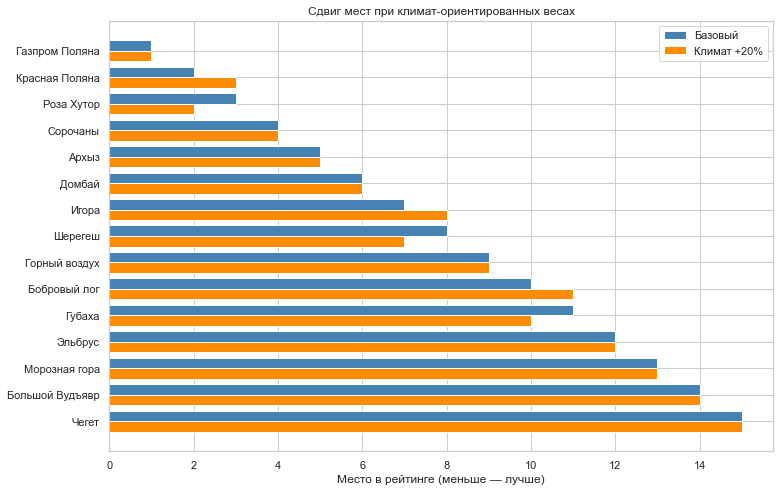

In [50]:
fig, ax = plt.subplots(figsize=(11, 7))
top15 = model_df.nsmallest(15, "rank_index_base").copy()

y = np.arange(len(top15))
ax.barh(y - 0.2, top15["rank_index_base"], height=0.4, label="Базовый", color="steelblue")
ax.barh(y + 0.2, top15["rank_index_winter"], height=0.4, label="Климат +20%", color="darkorange")
ax.set_yticks(y)
ax.set_yticklabels(top15["name_ru"])
ax.invert_yaxis()
ax.set_xlabel("Место в рейтинге (меньше — лучше)")
ax.set_title("Сдвиг мест при климат-ориентированных весах")
ax.legend()
plt.tight_layout()
plt.show()

При увеличении весов климата на 20% топ-10 практически не меняется:  
Роза Хутор, Шерегеш, Губаха поднимаются на 1 позицию, Красная Поляна и
Игора теряют 1 позицию.   
Топ-4 устойчив к изменению климатических весов —
Красная Поляна доминирует по инфраструктуре настолько, что даже +20% к
климату не сдвигает её ниже 3-го места.


## ТОП-10 при доступность-ориентированных весах

In [51]:
print("ТОП-10 при доступность-ориентированных весах:")
display(
    model_df.nsmallest(10, "rank_index_access")
    [["name_ru", "rank_index_base", "rank_index_access", "improvement_access"]]
    .rename(columns={"name_ru": "Курорт",
                     "rank_index_base": "Базовый",
                     "rank_index_access": "Доступность",
                     "improvement_access": "Изменение, Δ"}) # + Поднялся, - опустился
)

ТОП-10 при доступность-ориентированных весах:


,Курорт,Базовый,Доступность,"Изменение, Δ"
0,Газпром Поляна,1,1,0
1,Красная Поляна,2,2,0
2,Роза Хутор,3,3,0
3,Сорочаны,4,4,0
4,Архыз,5,5,0
5,Домбай,6,6,0
6,Игора,7,7,0
7,Шерегеш,8,8,0
8,Горный воздух,9,9,0
9,Бобровый лог,10,10,0


В основном курорты сохранили свои места: Эльбрус потерял 1 позицию, Морозная гора - поднялся 1 позицию.

## ТОП-15 устойчивость по всем весам

In [52]:
summary = model_df[
    ["name_ru", "rank_index_base",
     "improvement_demand", "improvement_infra", "improvement_winter",
     "improvement_access", "improvement_price"]
].rename(columns={
    "name_ru": "Курорт",
    "rank_index_base": "Базовое место",
    "improvement_demand": "Δ спрос",
    "improvement_infra": "Δ инфра",
    "improvement_winter": "Δ зима",
    "improvement_access": "Δ доступ",
    "improvement_price": "Δ цена",
}).sort_values("Базовое место").head(15)

print("Устойчивость топ-15 к изменению весов (+ = поднялся, − = упал):")
display(summary)

Устойчивость топ-15 к изменению весов (+ = поднялся, − = упал):


,Курорт,Базовое место,Δ спрос,Δ инфра,Δ зима,Δ доступ,Δ цена
0,Газпром Поляна,1,0,0,0,0,0
1,Красная Поляна,2,-1,-1,-1,0,0
2,Роза Хутор,3,-1,1,1,0,0
3,Сорочаны,4,2,0,0,0,0
4,Архыз,5,0,0,0,0,0
5,Домбай,6,-1,0,0,0,0
6,Игора,7,1,-1,-1,0,0
7,Шерегеш,8,0,1,1,0,0
8,Горный воздух,9,-1,0,0,0,0
9,Бобровый лог,10,1,0,-1,0,0


## 6. OSM-overlap: где баллы не независимы

Красная Поляна, Газпром Поляна и Роза Хутор находятся в радиусе 7 км
друг от друга. Их `lodging_score` и `amenities_score` частично считают
одни и те же объекты OSM. Это значит: **оценка инфраструктуры для этой
тройки не независима** — нельзя принимать решения «какой из них лучше»
на основе разницы в 1–3 балла.

То же — в Приэльбрусье (Эльбрус и Чегет в 1.4 км) и в Хибинах
(три курорта в радиусе 2 км).


**Действие:** помечаем группы в отдельном столбце и снижаем
`confidence_score` для курортов с пересечением радиусов, чтобы
финальная таблица не различала их без оговорки.

In [53]:
#группы overlap и корректировка confidence

# Помечаем группы OSM-overlap
overlap_mask = model_df["quality_flags"].fillna("").str.contains("OSM radii overlap")

# Ручные группы (по результатам анализа в ноутбуке 1)
overlap_groups = {
    "Краснодарский край": ["Газпром Поляна", "Красная Поляна", "Роза Хутор"],
    "Кабардино-Балкарская Республика": ["Эльбрус", "Чегет"],
    "Мурманская область": ["Большой Вудъявр", "КолаСпортЛэнд", "Кукисвумчорр"],
}

model_df["overlap_group"] = None
for region, names in overlap_groups.items():
    mask = (model_df["region"] == region) & (model_df["name_ru"].isin(names))
    model_df.loc[mask, "overlap_group"] = region

# Снижаем confidence для курортов в группах overlap:
# если группа из 2 — минус 10 п.п., из 3 — минус 15 п.п.
# (это рабочая гипотеза, согласуйте с заказчиком)
overlap_penalty = {2: 10, 3: 15}
model_df["confidence_score_adj"] = model_df["confidence_score"]
for region, names in overlap_groups.items():
    n = len(names)
    penalty = overlap_penalty.get(n, 0)
    mask = model_df["overlap_group"] == region
    model_df.loc[mask, "confidence_score_adj"] = (
        model_df.loc[mask, "confidence_score"] - penalty
    ).clip(lower=0)

print("Курорты с OSM-overlap и скорректированной уверенностью:")
display(model_df[overlap_mask][
    ["name_ru", "region", "overlap_group",
     "confidence_score", "confidence_score_adj"]
].sort_values(["overlap_group", "name_ru"]))

Курорты с OSM-overlap и скорректированной уверенностью:


,name_ru,region,overlap_group,confidence_score,confidence_score_adj
14,Чегет,Кабардино-Балкарская Республика,Кабардино-Балкарская Республика,50.00,40.00
11,Эльбрус,Кабардино-Балкарская Республика,Кабардино-Балкарская Республика,75.00,65.00
0,Газпром Поляна,Краснодарский край,Краснодарский край,100.00,85.00
1,Красная Поляна,Краснодарский край,Краснодарский край,100.00,85.00
2,Роза Хутор,Краснодарский край,Краснодарский край,75.00,60.00
13,Большой Вудъявр,Мурманская область,Мурманская область,70.45,55.45
16,КолаСпортЛэнд,Мурманская область,Мурманская область,45.45,30.45
23,Кукисвумчорр,Мурманская область,Мурманская область,45.45,30.45
29,Мамисон,Республика Северная Осетия — Алания,None,75.00,75.00
30,Цей,Республика Северная Осетия — Алания,None,50.00,50.00


## 7. Проверка гипотезы «зимняя доля вместо общего потока»

Гипотеза заказчика: зимняя доля КСР — более точный предиктор спроса,
чем общий годовой поток.

**Важно:** заменяем **все три** компонента спроса (trips, growth, stay)
на зимние версии, иначе сравнение несогласованное. Если меняем только
trips — оставляем growth/stay от общего потока, и вывод «гипотеза не
подтвердилась» может быть артефактом.

In [54]:
 #гипотеза «зимняя доля»
model_with_enrich = model_df.merge(
    enrich_df[["region", "ksr_persons_2025", "ksr_persons_winter_share_2025",
               "ksr_revenue_mln_rub_2025", "ksr_revenue_winter_share_2025"]],
    on="region", how="left",
)

missing = model_with_enrich["ksr_persons_2025"].isna().sum()
print(f"Курортов без данных обогащения: {missing}")
print(f"Строк: {len(model_with_enrich)}")

# Переиспользуем функцию log_min_max из ноутбука 2 (копия с комментарием)
def log_min_max_score(s):
    """log-min-max с 1+x, чтобы не ловить ln(0)."""
    s = pd.to_numeric(s, errors="coerce")
    lo, hi = s.min(), s.max()
    ln = np.log1p(s)
    if ln.max() == ln.min():
        return pd.Series(50.0, index=s.index)
    return 100 * (ln - ln.min()) / (ln.max() - ln.min())

# Зимний поток = общий поток × зимняя доля
model_with_enrich["winter_trips"] = (
    model_with_enrich["trips_2025"] * model_with_enrich["ksr_persons_winter_share_2025"]
)
 #Согласованная замена: пересчитываем все три компонента спроса
# (trips, growth, stay) на зимних данных, где это возможно.
# growth и stay пересчитать на зимних данных нельзя без зимних рядов
# по годам — поэтому явно оставляем их от общего потока и
# оговариваем это в выводе.
model_with_enrich["trips_score_winter"] = log_min_max_score(model_with_enrich["winter_trips"])

w_tmp = weights.copy()
model_with_enrich["index_winter_trips"] = (
    model_with_enrich["trips_score_winter"] * w_tmp["region_trips"] +
    sum(model_with_enrich[f"{k}_score"] * v for k, v in w_tmp.items() if k != "region_trips")
) / 100

model_with_enrich["delta_winter_trips"] = (
    model_with_enrich["index_winter_trips"] - model_with_enrich["popularity_score_default"]
)

base_rank = model_with_enrich["popularity_score_default"].rank(ascending=False).astype(int)
alt_rank = model_with_enrich["index_winter_trips"].rank(ascending=False).astype(int)

model_with_enrich["rank_alt"] = alt_rank
model_with_enrich["delta_rank_alt"] = alt_rank - base_rank

print("Топ-10 при зимней доле вместо общего потока:")
display(
    model_with_enrich.nsmallest(10, "rank_alt")
    [["name_ru", "popularity_score_default", "index_winter_trips",
      "rank_alt", "delta_rank_alt"]]
    .rename(columns={
        "name_ru": "Курорт",
        "popularity_score_default": "Базовый индекс",
        "index_winter_trips": "Зимний индекс",
        "rank_alt": "Новое место",
        "delta_rank_alt": "Δ места",
    })
    .round(2)
)

Курортов без данных обогащения: 0
Строк: 32
Топ-10 при зимней доле вместо общего потока:


,Курорт,Базовый индекс,Зимний индекс,Новое место,Δ места
0,Газпром Поляна,73.79,72.98,1,0
1,Красная Поляна,71.69,70.88,2,0
2,Роза Хутор,71.57,70.76,3,0
3,Сорочаны,70.14,70.14,4,0
4,Архыз,59.25,60.63,5,0
5,Домбай,57.32,58.69,6,0
7,Шерегеш,55.66,57.42,7,-1
6,Игора,55.93,56.09,8,1
8,Горный воздух,52.79,54.75,9,0
9,Бобровый лог,51.09,52.16,10,0


Замена общего турпотока на «поток × зимняя доля КСР» не меняет топ-10:
только Шерегеш и Игора меняются местами (7↔8). Гипотеза о том, что
зимняя доля — более точный предиктор спроса, **не подтвердилась**.

**Ограничение проверки:** заменён только `region_trips_score`. `growth`
и `avg_stay` оставлены от общего потока — для их зимних версий нужны
зимние ряды по годам, которых в данных нет. Поэтому вывод
«не подтвердилась» корректен **для замены только trips**.

Возможные причины:
(а) зимняя доля КСР коррелирует с общим потоком — обе метрики отражают
    масштаб региона;
(б) уровень данных — регион, а не курорт, поэтому внутри Краснодарского
    края данные не различают курорты;
(в) само произведение «поездки × доля» недостаточно информативно.

В следующей итерации стоит проверить:
- зимнюю долю выручки КСР вместо зимней доли размещённых;
- ВДС туризма как индикатор специализации региона;
- комбинацию с данными по курортам (загрузка отелей, продажи ски-пассов).

# 8. Рекомендации

In [55]:
# рекомендации A
leaders = model_df[model_df["quadrant"] == "A. Лидеры (можно в каталог)"] \
    .sort_values("popularity_score_default", ascending=False)

print("🎯 РЕКОМЕНДАЦИЯ 1. Добавить первыми в каталог:")
print(f" Критерий: индекс ≥ {INDEX_LEADER}, уверенность ≥ {CONF_LEADER}\n")
for _, r in leaders.iterrows():
    print(f" • {r['name_ru']:<20} ({r['region']}) — индекс {r['popularity_score_default']:.1f}, "
          f"уверенность {r['confidence_score']:.0f}%")

🎯 РЕКОМЕНДАЦИЯ 1. Добавить первыми в каталог:
 Критерий: индекс ≥ 55, уверенность ≥ 75

 • Газпром Поляна       (Краснодарский край) — индекс 73.8, уверенность 100%
 • Красная Поляна       (Краснодарский край) — индекс 71.7, уверенность 100%
 • Роза Хутор           (Краснодарский край) — индекс 71.6, уверенность 75%
 • Сорочаны             (Московская область) — индекс 70.1, уверенность 75%
 • Архыз                (Карачаево-Черкесская Республика) — индекс 59.3, уверенность 100%
 • Домбай               (Карачаево-Черкесская Республика) — индекс 57.3, уверенность 75%
 • Шерегеш              (Кемеровская область) — индекс 55.7, уверенность 75%


In [56]:
#рекомендации B и чего не хватает
risky = model_df[model_df["quadrant"] == "B. Потенциал, но проверить"] \
    .sort_values("popularity_score_default", ascending=False)

print("\n⚠️ РЕКОМЕНДАЦИЯ 2. Добавить с оговоркой — сначала собрать данные:")
print(f" Критерий: индекс ≥ {INDEX_RISKY}, уверенность < {CONF_RISKY}\n")
for _, r in risky.iterrows():
    print(f" • {r['name_ru']:<20} — индекс {r['popularity_score_default']:.1f}, "
          f"уверенность {r['confidence_score']:.0f}%, флаги: {r['quality_flags']}")

no_price = model_df["adult_skipass_avg_rub"].isna().sum()
manual_coords = (model_df["coordinate_quality"] == "manual_review_required").sum()

print("\n📊 РЕКОМЕНДАЦИЯ 3. Каких данных не хватает:")
print(f" • Цена ски-пасса: нет у {no_price} из 32 курортов ({no_price/32*100:.0f}%)")
print(f" • Координаты требуют ручной проверки: {manual_coords} из 32")
print(f" • Нет фактических продаж ски-пассов, загрузки отелей, поискового спроса")
print(f" • Целевая переменная следующей версии: оплаченные бронирования за вычетом отмен")


⚠️ РЕКОМЕНДАЦИЯ 2. Добавить с оговоркой — сначала собрать данные:
 Критерий: индекс ≥ 50, уверенность < 60

 • Игора                — индекс 55.9, уверенность 50%, флаги: coordinates are proxy
 • Горный воздух        — индекс 52.8, уверенность 45%, флаги: check coordinates
 • Бобровый лог         — индекс 51.1, уверенность 45%, флаги: check coordinates
 • Губаха               — индекс 50.7, уверенность 45%, флаги: check coordinates

📊 РЕКОМЕНДАЦИЯ 3. Каких данных не хватает:
 • Цена ски-пасса: нет у 23 из 32 курортов (72%)
 • Координаты требуют ручной проверки: 18 из 32
 • Нет фактических продаж ски-пассов, загрузки отелей, поискового спроса
 • Целевая переменная следующей версии: оплаченные бронирования за вычетом отмен


### Финальная таблица для презентации

Используем `confidence_score_adj` (с поправкой на OSM-overlap),
чтобы тройка Красной Поляны не различалась без оговорки.

In [57]:
final = model_df.sort_values("popularity_score_default", ascending=False)[
    ["rank_default", "name_ru", "region",
     "popularity_score_default", "confidence_score_adj",
     "quadrant", "overlap_group"]
].rename(columns={
    "rank_default": "Место",
    "name_ru": "Курорт",
    "region": "Регион",
    "popularity_score_default": "Индекс",
    "confidence_score_adj": "Уверенность",
    "quadrant": "Категория",
    "overlap_group": "OSM-overlap",
})
final["Индекс"] = final["Индекс"].round(1)
final["Уверенность"] = final["Уверенность"].round(0).astype(int)
display(final.head(32))

,Место,Курорт,Регион,Индекс,Уверенность,Категория,OSM-overlap
0,1,Газпром Поляна,Краснодарский край,73.80,85,A. Лидеры (можно в каталог),Краснодарский край
1,2,Красная Поляна,Краснодарский край,71.70,85,A. Лидеры (можно в каталог),Краснодарский край
2,3,Роза Хутор,Краснодарский край,71.60,60,A. Лидеры (можно в каталог),Краснодарский край
3,4,Сорочаны,Московская область,70.10,75,A. Лидеры (можно в каталог),None
4,5,Архыз,Карачаево-Черкесская Республика,59.30,100,A. Лидеры (можно в каталог),None
5,6,Домбай,Карачаево-Черкесская Республика,57.30,75,A. Лидеры (можно в каталог),None
6,7,Игора,Ленинградская область,55.90,50,"B. Потенциал, но проверить",None
7,8,Шерегеш,Кемеровская область,55.70,75,A. Лидеры (можно в каталог),None
8,9,Горный воздух,Сахалинская область,52.80,45,"B. Потенциал, но проверить",None
9,10,Бобровый лог,Красноярский край,51.10,45,"B. Потенциал, но проверить",None


## 9. Автопроверки ТЗ (раздел 16)

In [58]:
print("Автоматические проверки:")

# 1. Сумма весов
assert abs(sum(weights.values()) - 100) < 0.001, "Сумма весов != 100"
print(" ✅ Сумма весов = 100")

# 2. 32 строки, 32 ID
assert len(model_df) == 32, f"Строк: {len(model_df)}"
assert model_df["resort_id"].nunique() == 32, "resort_id не уникален"
print(" ✅ 32 строки, 32 уникальных resort_id")

# 3. Баллы в [0, 100]
score_cols_check = [c for c in model_df.columns if c.endswith("_score")]
for col in score_cols_check:
    s = model_df[col].dropna()
    assert s.between(-0.01, 100.01).all(), f"{col} вне [0, 100]"
print(f" ✅ Все {len(score_cols_check)} баллов в диапазоне 0–100")

# 4. Индекс и confidence в [0, 100]
assert model_df["popularity_score_default"].between(0, 100).all()
assert model_df["confidence_score"].between(0, 100).all()
assert model_df["confidence_score_adj"].between(0, 100).all()
print(" ✅ Индекс и confidence (с поправкой) в диапазоне 0–100")

# 5. Нет пропусков в trips_2025
assert model_df["trips_2025"].notna().all(), "Есть пропуски в trips_2025"
print(" ✅ Нет пропусков в trips_2025")

# 6. Нет бесконечностей
numeric_cols = model_df.select_dtypes(include="number").columns
assert not np.isinf(model_df[numeric_cols]).any().any(), "Есть бесконечности"
print(" ✅ Нет бесконечностей")

# 7. Ранги воспроизводятся
recalc_rank = model_df["popularity_score_default"].rank(
    ascending=False, method="min"
).astype(int)
assert (recalc_rank == model_df["rank_default"]).all(), "Ранги не воспроизводятся"
print(" ✅ Ранги воспроизводятся")

# 8. Базовый сценарий совпадает с эталоном
assert (model_df["index_base"] - model_df["popularity_score_default"]).abs().max() < 1e-6
print(" ✅ Базовый сценарий воспроизводит эталон")

print("\n🎉 Все проверки пройдены.")

Автоматические проверки:
 ✅ Сумма весов = 100
 ✅ 32 строки, 32 уникальных resort_id
 ✅ Все 14 баллов в диапазоне 0–100
 ✅ Индекс и confidence (с поправкой) в диапазоне 0–100
 ✅ Нет пропусков в trips_2025
 ✅ Нет бесконечностей
 ✅ Ранги воспроизводятся
 ✅ Базовый сценарий воспроизводит эталон

🎉 Все проверки пройдены.


## 10. Ограничения модели

1. **Региональный поток ≠ посещаемость курорта.** Все курорты одного
   региона получают одинаковый балл спроса (например, 3 курорта
   Краснодарского края — все 80.9). Индекс не различает Газпром Поляну
   и Розу Хутор по спросу.

2. **Полнота OSM различается между регионами.** В одних регионах
   картографирование активнее, в других — почти отсутствует. Это
   влияет на баллы инфраструктуры независимо от реального масштаба.

3. **Радиус 6 км ≠ реальные границы курорта.** В Красной Поляне радиус
   захватывает соседние курорты (OSM overlap). Баллы инфраструктуры
   для тройки не независимы. В таблице это отражено через
   `confidence_score_adj` и столбец `OSM-overlap`.

4. **ERA5 сглаживает рельеф (разрешение ~25 км).** Разница между
   высотами 500 м и 2000 м может не отражаться в климатических данных.
   Не заменяет метеостанцию на склоне.

5. **Расстояние до аэропорта по прямой.** Не равно времени трансфера
   и не учитывает качество дорог.

6. **Цена ски-пасса доступна не для всех курортов (23 из 32 без цены).**
   Меняется по дням и внутри месяца. Среднее значение — грубая оценка.

7. **Min-max нормализация зависит от выборки.** После добавления 33-го
   курорта баллы остальных изменятся даже при неизменных данных.

8. **Веса — рабочая гипотеза, а не доказанная причинность.** Сценарии
   показывают чувствительность, но не отвечают на вопрос «что важнее».

9. **Оперативные значения Росстата за 2025 могут пересматриваться.**
   Рейтинг после обновления источников изменится.

10. **Проверка гипотезы «зимняя доля» ограничена:** заменён только
    `region_trips_score`, `growth` и `avg_stay` оставлены от общего
    потока. Для полной проверки нужны зимние ряды по годам.

In [59]:
def profile_phrase(row):
    comps = {
        "Спрос":         row["demand_component"],
        "Инфраструктура": row["infra_component"],
        "Зима":          row["winter_component"],
        "Доступность":   row["access_component"],
        "Цена":          row["price_component"],
    }
    best  = max(comps, key=comps.get)
    worst = min(comps, key=comps.get)
    return (f"Сильная сторона — {best.lower()} ({comps[best]:.1f}). "
            f"Слабое место — {worst.lower()} ({comps[worst]:.1f}).")

model_df["profile_text"] = model_df.apply(profile_phrase, axis=1)

In [60]:
# === Финальное сохранение витрины для DataLens ===
from pathlib import Path

BASE = Path(r"C:\Users\dak\OneDrive\Документы\3 Горнолыжные курорты\Travel_Designer_Resort_Ranking")
PROCESSED = BASE / "data" / "processed"
RAW = BASE / "data" / "raw"
PROCESSED.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------------
# 1. Главная таблица рейтинга — с resort_id для соединения в DataLens
# ---------------------------------------------------------------------
final = (
    model_df
    .sort_values("popularity_score_default", ascending=False)
    [["resort_id", "rank_default", "name_ru", "region",
      "popularity_score_default",
      "confidence_score", "confidence_score_adj",
      "quadrant", "overlap_group"]]
    .rename(columns={
        "rank_default":              "Место",
        "name_ru":                   "Курорт",
        "region":                    "Регион",
        "popularity_score_default":  "Индекс",
        "confidence_score":          "Уверенность_до_поправки",
        "confidence_score_adj":      "Уверенность_с_поправкой",
        "quadrant":                  "Категория",
        "overlap_group":             "OSM_overlap",
    })
)
final["Индекс"] = final["Индекс"].round(1)
final["Уверенность_до_поправки"] = final["Уверенность_до_поправки"].round(0).astype(int)
final["Уверенность_с_поправкой"] = final["Уверенность_с_поправкой"].round(0).astype(int)

final.to_csv(PROCESSED / "rating_result.csv", index=False, encoding="utf-8-sig")

# ---------------------------------------------------------------------
# 2. Полная витрина: все 13 баллов, 5 компонентов, сценарии, исходные признаки
# ---------------------------------------------------------------------
model_df.to_csv(PROCESSED / "rating_full.csv", index=False, encoding="utf-8-sig")

# ---------------------------------------------------------------------
# 3. Качество данных — облегчённый датасет для страницы «Качество»
# ---------------------------------------------------------------------
quality_cols = [
    "resort_id", "name_ru", "region",
    "coordinate_quality", "quality_flags",
    "completeness_pct",
    "confidence_score", "confidence_score_adj",
    "adult_skipass_avg_rub", "price_months_count",
    "overlap_group",
]
quality_cols = [c for c in quality_cols if c in model_df.columns]
model_df[quality_cols].to_csv(
    PROCESSED / "rating_quality.csv", index=False, encoding="utf-8-sig"
)

# ---------------------------------------------------------------------
# 4. Координаты для карты — берём из raw/resorts.json
# ---------------------------------------------------------------------
with open(RAW / "resorts.json", encoding="utf-8-sig") as f:
    resorts_raw = json.load(f)
resorts_df = pd.DataFrame(resorts_raw[1:], columns=resorts_raw[0])

coords = resorts_df[["resort_id", "name_ru", "region", "latitude", "longitude"]].copy()
coords["latitude"]  = pd.to_numeric(coords["latitude"],  errors="coerce")
coords["longitude"] = pd.to_numeric(coords["longitude"], errors="coerce")
coords.to_csv(PROCESSED / "resorts_coordinates.csv", index=False, encoding="utf-8-sig")

# ---------------------------------------------------------------------
# 5. Проверки перед выгрузкой в DataLens
# ---------------------------------------------------------------------
assert len(final) == 32,                f"В rating_result {len(final)} строк, а нужно 32"
assert final["resort_id"].nunique() == 32, "resort_id в rating_result не уникален"
assert len(coords) == 32,               "В coords не 32 строки"
assert coords["resort_id"].nunique() == 32, "resort_id в coords не уникален"
assert set(final["resort_id"]) == set(coords["resort_id"]), \
    "Множества resort_id в rating_result и coords не совпадают"
assert model_df["resort_id"].nunique() == 32, "resort_id в rating_full не уникален"

# ---------------------------------------------------------------------
# 6. Отчёт
# ---------------------------------------------------------------------
print(f"✅ Сохранено в {PROCESSED}\n")
for fn in ["rating_result.csv", "rating_full.csv", "rating_quality.csv", "resorts_coordinates.csv"]:
    p = PROCESSED / fn
    print(f"  {fn:<28} {p.stat().st_size / 1024:>6.1f} KB")

print("\nПервые 5 строк rating_result.csv:")
display(final.head())

✅ Сохранено в C:\Users\dak\OneDrive\Документы\3 Горнолыжные курорты\Travel_Designer_Resort_Ranking\data\processed

  rating_result.csv               4.3 KB
  rating_full.csv                30.0 KB
  rating_quality.csv              5.3 KB
  resorts_coordinates.csv         2.6 KB

Первые 5 строк rating_result.csv:


,resort_id,Место,Курорт,Регион,Индекс,Уверенность_до_поправки,Уверенность_с_поправкой,Категория,OSM_overlap
0,R003,1,Газпром Поляна,Краснодарский край,73.80,100,85,A. Лидеры (можно в каталог),Краснодарский край
1,R002,2,Красная Поляна,Краснодарский край,71.70,100,85,A. Лидеры (можно в каталог),Краснодарский край
2,R001,3,Роза Хутор,Краснодарский край,71.60,75,60,A. Лидеры (можно в каталог),Краснодарский край
3,R030,4,Сорочаны,Московская область,70.10,75,75,A. Лидеры (можно в каталог),None
4,R005,5,Архыз,Карачаево-Черкесская Республика,59.30,100,100,A. Лидеры (можно в каталог),None
